![title](https://i.imgur.com/XPBIVRh.png)
 <!https://imgur.com/XPBIVRh>
---



# Task 2 - Autoregressive


The goals of this assignment to build and train:

    * Char-LSTM for Character-level Language Modeling using Sonnet dataset.
    * PixelRNN Autoregressive Image Generation for MNIST dataset.
    * PixelCNN Autoregressive Image Generation for MNIST dataset.


Write down your Name and Student ID

In [215]:
## --- start your code here ----

NIM  = 103012300057
Nama = "Muhammad Ravi Athallah"

## --- end your code here ----

---
---
#[Part 0] Environment Setup & Dataset Download



---
## 1 - Import Libraries

Import required libraries

In [216]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision.datasets as dset
import torchvision.transforms as T

from torch.utils.data import DataLoader

import numpy as np
import matplotlib.pyplot as plt
import urllib.request
from tabulate import tabulate

%matplotlib inline
# %load_ext autoreload
# %autoreload 2

plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


In [217]:
# --- JANGAN diubah: seed & parameter unik per mahasiswa, diturunkan dari NIM ---
import hashlib

_nim_str = str(NIM).strip()
SEED = int(hashlib.sha256(_nim_str.encode()).hexdigest(), 16) % (2**31)

torch.manual_seed(SEED)
np.random.seed(SEED)
print('Seed unik (dari NIM):', SEED)


Seed unik (dari NIM): 446089093


---
## 2 - GPU Preparation

In [218]:
USE_GPU = True

dtype = torch.float32 # we will be using float throughout this tutorial

if USE_GPU and torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print('using device:', device)

using device: cuda


---
## 3 - Metric Visualizer

In [219]:
def visualize_loss(epoch, history, title="Loss History", label="loss"):
  plt.figure(figsize=(8, 5))
  plt.plot(range(1, epoch + 1), history, marker='o', label=label)
  plt.title(title)
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.grid(True)
  plt.legend()
  plt.show()

---
## 4 - Image Sample Visualizer

In [220]:
def visualize_samples(samples, title='Generated Images'):
  fig, axes = plt.subplots(4, 4, figsize=(6, 6))
  for i, ax in enumerate(axes.flat):
      ax.imshow(samples[i], cmap='gray')
      ax.axis('off')
  plt.suptitle(title, fontsize=14)
  plt.show()

---
---
#[Part 1] Character-level Language Generation using LSTM

In this part, you will build, train, and evaluate a Char-LSTM (Character-level Long Short-Term Memory) network from scratch using the PyTorch framework.

Unlike word-level NLP models that process full words as tokens, a Char-LSTM operates at the atomic level of language (letters, spaces, and punctuation).

The magic of this model lies in its ability to independently grasp grammar structures, spelling patterns, capitalization rules, and stylistic nuances solely by analyzing raw text.

Once trained successfully, your model will act as an AI Creative Writer, capable of generating brand-new text sequences that mimic the tone and style of the training data.

For this experiment, you will train your model on a collection of classic "Sonnet" poems by William Shakespeare, fetched directly from the vLLM project's official benchmark repository.

---
## 1 - Data Preparation
Download the Sonnet dataset

In [221]:
# vLLM sonnet.txt sempat tidak tersedia (404) per Oktober 2026, jadi default
# dipindah ke Tiny Shakespeare (dataset standar untuk char-RNN, stabil selama
# bertahun-tahun). Teks dipotong ke 200.000 karakter pertama supaya waktu
# training tetap wajar (dataset aslinya >1MB kalau dipakai penuh).
url = "https://raw.githubusercontent.com/karpathy/char-rnn/refs/heads/master/data/tinyshakespeare/input.txt"

# Dataset alternatif lain kalau mau coba
# url = "https://raw.githubusercontent.com/vllm-project/vllm/refs/heads/main/benchmarks/sonnet.txt" # Sonnet (sempat 404, cek dulu sebelum pakai)
# url = "https://gist.githubusercontent.com/nwhoffman/20d15b1a8cf2988a2a008d3bd73ff76e/raw/e1660f42e20e0421dde26c48fee9f56493277922/wonderland.txt" # Alice in Wonderland (kecil, ~13K karakter)

response = urllib.request.urlopen(url)
text     = response.read().decode('utf-8')
text     = text[:200_000]  # batasi ukuran supaya training tetap cepat

print(f"Dataset Length: {len(text)} characters")
print("Sample text:", text[:100])


Dataset Length: 200000 characters
Sample text: First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You


Build unique characters set

In [222]:
chars      = sorted(list(set(text)))
vocab_size = len(chars)

print(f"Vocabulary size: {vocab_size} distinct characters")

Vocabulary size: 62 distinct characters


---
## 2 - Vocabulary & Character Mapping

To pass characters into a neural network, we must build a vocabulary mapping uniquely representing every distinct character with a numeric index.

In [223]:
char_to_int = {ch: i for i, ch in enumerate(chars)}
int_to_char = {i: ch for i, ch in enumerate(chars)}

print("Sample mapping:", list(char_to_int.items())[:10])

Sample mapping: [('\n', 0), (' ', 1), ('!', 2), ('&', 3), ("'", 4), (',', 5), ('-', 6), ('.', 7), (':', 8), (';', 9)]


---
## 3 - Mini-batch Processing Data Loader

We need to transform the full raw text sequence into structured sequences of length `seq_length`.

For character prediction, the input sequence is `text[t:t+seq_length]` and the expected targets are shifted by one step ahead: `text[t+1:t+seq_length+1]`.

---
#### <font color='red'>**EXERCISE:** </font>

    Extract input (x) and target (y) slices from encoded array
    * x should be the slice of encoded from index 'n' to 'n + seq_length'
    * y should be the slice of encoded from index 'n + 1' to 'n + seq_length + 1'

In [224]:
def get_batches(text, seq_length, batch_size):
    """
    Generates mini-batches from text array data.
    """
    # Convert full text to indexed integer list
    encoded = np.array([char_to_int[ch] for ch in text], dtype=np.int32)

    # Number of characters per batch structure
    chars_per_batch = batch_size * seq_length
    n_batches = len(encoded) // chars_per_batch

    # Keeping only full batches
    encoded = encoded[:n_batches * chars_per_batch]

    # Reshape text elements across rows matching batch layout
    encoded = encoded.reshape((batch_size, -1))


    ############################################################################
    # TODO: Extract input (x) and target (y) slices from encoded array         #
    ############################################################################

    for n in range(0, encoded.shape[1], seq_length):
        # Check if we have enough sequence length left for targeting
        if n + seq_length >= encoded.shape[1]:
            break

        # x should be the slice of encoded from index 'n' to 'n + seq_length'
        x = encoded[:, n:n+seq_length]

        # y should be the slice of encoded from index 'n + 1' to 'n + seq_length + 1'
        y = encoded[:, n+1:n+seq_length+1]

    ############################################################################
    #                             END OF YOUR CODE                             #
    ############################################################################

        yield torch.tensor(x, dtype=torch.long), torch.tensor(y, dtype=torch.long)

check your implementation

In [225]:

test_batch_size, test_seq_length = 8, 20
sample_batches     = list(get_batches(text, test_seq_length, test_batch_size))
x_sample, y_sample = sample_batches[0]

print("x_sample shape: ", x_sample.shape, ", y_sample shape: ", y_sample.shape)

assert x_sample.shape == (test_batch_size, test_seq_length), f"Expected input shape {(test_batch_size, test_seq_length)}, got {x_sample.shape}"
assert y_sample.shape == (test_batch_size, test_seq_length), f"Expected target shape {(test_batch_size, test_seq_length)}, got {y_sample.shape}"
print("\nExercise check passed! Batch tensor construction shapes are correct.")


x_sample shape:  torch.Size([8, 20]) , y_sample shape:  torch.Size([8, 20])

Exercise check passed! Batch tensor construction shapes are correct.


**EXPECTED OUTPUT**:
<pre>
x_sample shape:  torch.Size([8, 20]) , y_sample shape:  torch.Size([8, 20])

---
## 4 - Char-LSTM Architecture

Define a modular network inheriting from `nn.Module`.

We use an embedding layer to encode indices, an LSTM layer, and a dense output layer projecting hidden output nodes to match our vocab dimensions.

---
#### <font color='red'>**EXERCISE:** </font>

    Define standard network sub-components
    1. Embedding layer linking vocabulary to embedding_dim dimensions
    2. PyTorch standard nn.LSTM configuring features batch_first=True and custom drop_prob
    3. Dropout regularization step before final projecting transformation
    4. Dense Linear layout output transforming hidden state outputs to size of characters

    Implement the forward computation steps
    1. Forward features through the embedding layer
    2. Execute modern LSTM calculations with hidden structures input tracking
    3. Add dropout to your out-tensor
    4. Reshape out-tensor sizes to (-1, hidden_dim) and pass to FC linear module

In [226]:
class CharLSTM(nn.Module):

################################################################################
# TODO: Complete the model architecture                                        #
################################################################################

    def __init__(self, vocab_size, embedding_dim, hidden_dim, n_layers=2, drop_prob=0.5):
        super(CharLSTM, self).__init__()
        self.drop_prob  = drop_prob
        self.n_layers   = n_layers
        self.hidden_dim = hidden_dim

        # Define the Embedding Layer
        # add nn.Embedding() with input 'vocab_size' and 'embedding_dim'
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # Define the stacked LSTM Layer
        # add nn.LSTM() with input 'embedding_dim', 'hidden_dim', and 'n_layers'
        # set dropout = drop_prob and batch_first=True
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, n_layers, dropout=drop_prob, batch_first=True)

        # Define the Dropout Layer for regularisation
        # add nn.Dropout() with input 'drop_prob'
        self.dropout = nn.Dropout(drop_prob)

        # Define the fully-connected Output Layer
        # add nn.Linear() with input 'hidden_dim' and 'vocab_size'
        self.fc = nn.Linear(hidden_dim, vocab_size)


    def forward(self, x, hidden):
        """
        Forward pass across structural cells
        """

        # Pass inputs through embedding
        # call self.embedding() graph using input x
        embedded = self.embedding(x)

        # Pass embedding through LSTM
        # call self.lstm() graph using input 'embedded' and 'hidden'
        out, hidden = self.lstm(embedded, hidden)

        # Pass LSTM output through Dropout
        # call self.dropout() graph using input 'out'
        out = self.dropout(out)

        # Reshape to match FC layer requirements
        # flatten 'out' using out.reshape() to shape (-1, self.hidden_dim)
        out = out.contiguous().view(-1, self.hidden_dim)

        # Put through Fully-Connected Layer
        # call self.fc() graph using input 'out'
        out = self.fc(out)

        return out, hidden

################################################################################
#                                 END OF YOUR CODE                             #
################################################################################


    def init_hidden(self, batch_size, device):
        """ Initializes hidden states matching target weight dimensions """
        weight = next(self.parameters()).data
        hidden = (weight.new_zeros(self.n_layers, batch_size, self.hidden_dim).to(device),
                  weight.new_zeros(self.n_layers, batch_size, self.hidden_dim).to(device))
        return hidden


check your implementation

In [227]:
# Sanity Check
test_model = CharLSTM(vocab_size=vocab_size, embedding_dim=64, hidden_dim=128).to(device)

test_hidden = test_model.init_hidden(test_batch_size, device)

test_out, test_hid = test_model(x_sample.to(device), test_hidden)

expected_out_shape = (test_batch_size * test_seq_length, vocab_size)

print("test_out shape: ", test_out.shape, "\n")
print(test_model)

assert test_out.shape == expected_out_shape, f"Expected output size {expected_out_shape}, but got {test_out.shape}"
print("\nExercise check passed! CharLSTM forward pass matches standard sizes.")

test_out shape:  torch.Size([160, 62]) 

CharLSTM(
  (embedding): Embedding(62, 64)
  (lstm): LSTM(64, 128, num_layers=2, batch_first=True, dropout=0.5)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=128, out_features=62, bias=True)
)

Exercise check passed! CharLSTM forward pass matches standard sizes.


**EXPECTED OUTPUT**:
<pre>
test_out shape:  torch.Size([160, V])  # V = jumlah karakter unik di dataset (sekitar 60an)

CharLSTM(
  (embedding): Embedding(V, 64)
  (lstm): LSTM(64, 128, num_layers=2, batch_first=True, dropout=0.5)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=128, out_features=V, bias=True)
)

---
## 5 - Initialize Model and Optimizer

Initialize your model.
You can try and change the embedding and hidden dimensions

In [228]:
embedding_dim = 96 + (SEED % 5) * 16   # unik per mahasiswa (dari NIM), jangan diubah manual
hidden_dim    = 192 + (SEED % 4) * 32  # unik per mahasiswa (dari NIM), jangan diubah manual

lstm_model = CharLSTM(vocab_size, embedding_dim, hidden_dim, n_layers=2).to(device)

print(lstm_model)


CharLSTM(
  (embedding): Embedding(62, 144)
  (lstm): LSTM(144, 224, num_layers=2, batch_first=True, dropout=0.5)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=224, out_features=62, bias=True)
)


**EXPECTED OUTPUT** (contoh struktur - angka `embedding_dim`/`hidden_dim` Anda akan berbeda karena diturunkan dari NIM, tapi bentuknya harus sama):
<pre>
CharLSTM(
  (embedding): Embedding(V, embedding_dim)  # V = jumlah karakter unik di dataset
  (lstm): LSTM(embedding_dim, hidden_dim, num_layers=2, batch_first=True, dropout=0.5)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=hidden_dim, out_features=V, bias=True)
)
</pre>

Initialize optimizer and learning rate

In [229]:
lstm_learning_rate = 0.005

lstm_optimizer = optim.Adam(lstm_model.parameters(), lr=lstm_learning_rate)
lstm_criterion = nn.CrossEntropyLoss()

---
## 6 - Training Loop

Fill in the critical steps within the inner multi-batch iteration loop: zeroing gradients, calculating modern cross-entropy objectives, and performing loss backpropagation steps.

---
#### <font color='red'>**EXERCISE:** </font>

    Complete the missing execution parts
    1. Zero out model structural accumulation gradients
    2. Fetch network execution responses by invoking model(x, h)
    3. Calculate Cross Entropy Loss targeting y reshaped into a flat vector using view(-1)
    4. Invoke .backward() to calculate gradients
    


In [230]:
def lstm_train_module(model, optimizer, epochs=1, batch_size=64, seq_length=50, clip_value=5.0, print_every=20):

  loss_history = []

  print("Starting LSTM training loop...")
  model.train()
  for epoch in range(1, epochs + 1):
      h = model.init_hidden(batch_size, device)
      epoch_losses = []

      for x, y in get_batches(text, seq_length, batch_size):
          x, y = x.to(device), y.to(device)

          # Detach hidden states variables to prevent exploding tracking history
          h = tuple([each.data for each in h])

          ######################################################################
          # TODO: Complete the training function                               #
          ######################################################################

          # Zero out accumulated gradients for the variables which the optimizer
          # call zero_grad() from optimizer
          optimizer.zero_grad()

          # Forward pass output
          # call model() with input 'x' and 'h'
          out, h = model(x, h)

          # Calculate Loss
          # call lstm_criterion() with input 'out' and y.view(-1)
          loss = lstm_criterion(out, y.view(-1))

          # Backward pass to compute the gradients
          # call backward() function from 'loss'
          loss.backward()

          # Clip gradients to prevent exploding
          nn.utils.clip_grad_norm_(model.parameters(), clip_value)

          # Update weights using the optimizer step()
          # call step() function from 'optimizer'
          optimizer.step()

          ######################################################################
          #                           END OF YOUR CODE                         #
          ######################################################################

          epoch_losses.append(loss.item())

      avg_loss = np.mean(epoch_losses)
      loss_history.append(avg_loss)

      if epoch % print_every == 0 or epoch == 1:
          print(f"Epoch {epoch}/{epochs} --- Avg Loss: {avg_loss:.4f}")

  print("Training completed!")
  return loss_history

Train your model

In [231]:
# Training hyperparameters config
lstm_epochs     = 100 # change for longer training and better results

lstm_batch_size = 64
seq_length      = 50
clip_value      = 5.0 # gradient clipping boundary

lstm_history = lstm_train_module(lstm_model, lstm_optimizer, lstm_epochs, lstm_batch_size, seq_length, clip_value)

assert lstm_history[-1]<1.5, f"Loss is not low enough, train more"
print("\nExercise check passed! CharLSTM has been sufficiently trained.")


Starting LSTM training loop...
Epoch 1/100 --- Avg Loss: 2.5722
Epoch 20/100 --- Avg Loss: 1.4583
Epoch 40/100 --- Avg Loss: 1.3914
Epoch 60/100 --- Avg Loss: 1.3612
Epoch 80/100 --- Avg Loss: 1.3492
Epoch 100/100 --- Avg Loss: 1.3527
Training completed!

Exercise check passed! CharLSTM has been sufficiently trained.


**EXPECTED OUTPUT**:
<pre>
Avg Loss should start at around 2.5-3 and end at around 1.3-1.5 with 100 epochs
(angka pasti bisa sedikit berbeda tergantung embedding_dim/hidden_dim milik NIM Anda)


---
## 7 - Metrics Visualization

Visualizing Loss during training

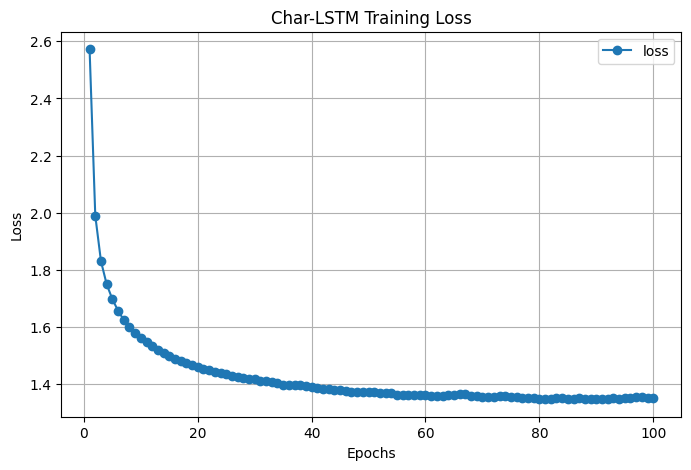

In [232]:
visualize_loss(lstm_epochs, lstm_history, title='Char-LSTM Training Loss')

---
## 8 - Model Inference

Let's check our model's capacity by auto-generating sequences based on an input seed string phrase.

In [233]:
def sample_next_char(output, temperature=1.0):
    """ Scales linear logits with temperature metrics to sample character probabilities """
    # Divide output logits by temperature
    logits = output[-1].data / temperature

    # Convert logits into soft probability distributions
    exp_logits = torch.exp(logits)
    probs      = exp_logits / torch.sum(exp_logits)

    # Draw character index index selection sampling
    char_idx = torch.multinomial(probs, 1).item()

    return char_idx

---
#### <font color='red'>**EXERCISE:** </font>

    Auto-generate the remaining number of characters up to top_size ###
    In every loop step:
    1. Convert current_char_idx into a 2D long Tensor formatted matching size [[idx]]
    2. Forward pass into the model with tracking state 'h' to get updated output and hidden state
    3. Pick next character via sample_next_char utility function tracking custom temperature values
    4. Convert chosen integer id to regular character and append it to generated_chars
    

In [234]:
def generate_text(model, top_size, seed_str='The ', temperature=0.8):
    model.eval()
    device = next(model.parameters()).device

    # Initialize output container with original characters
    generated_chars = list(seed_str)

    # Prime the network state using character elements available inside the seed string
    h = model.init_hidden(1, device)
    for ch in seed_str:
        char_tensor = torch.tensor([[char_to_int[ch]]], dtype=torch.long).to(device)
        output, h = model(char_tensor, h)

    # Sample the next character after processing the initial seed
    current_char_idx = sample_next_char(output, temperature)
    generated_chars.append(int_to_char[current_char_idx])

    ############################################################################
    # TODO: Complete the inference function                                    #
    ############################################################################

    for _ in range(top_size - len(seed_str)):

        # Convert current_char_idx into a 2D long Tensor formatted matching size
        char_tensor = torch.tensor([[current_char_idx]], dtype=torch.long).to(device)

        # Forward pass into the model
        # call model() with input 'char_tensor' and 'h'
        output, h = model(char_tensor, h)

        # Pick next character via sample_next_char utility function
        # call sample_next_char() with inputs 'output' and 'temperature'
        current_char_idx = sample_next_char(output, temperature)

        # Convert chosen integer id to regular character and append it to generated_chars
        # call int_to_char() with input 'current_char_idx'
        generated_chars.append(int_to_char[current_char_idx])

    ############################################################################
    #                             END OF YOUR CODE                             #
    ############################################################################

    return ''.join(generated_chars)

Run inference generation

In [235]:
seed_phrase = "Shall I compare "
generated_result = generate_text(lstm_model, top_size=500, seed_str=seed_phrase, temperature=0.7)

print("\n--- FINAL GENERATED TEXT OUTPUT ---")
print(generated_result)

# Expected Output Verification
assert generated_result.startswith(seed_phrase), "Generated output must begin with the provided seed string!"
assert len(generated_result) >= 200, "Generated string length must match specified top_size parameters!"
print("\nAll validation checks successfully completed! Exercise solution works perfectly.")


--- FINAL GENERATED TEXT OUTPUT ---
Shall I compare the tribunes,
And father such a can remain on to his country,
Only the voices some dooth and so,
To say it that make a mory and intime.

CORIOLANUS:
This so, we have promise.

First Citizen:
And nothing it for thee and a way with the were of Rome,
He call him send to you our sword of saw all the soul,
But I do wrank his awmorting gentle state.

Third Servingman:
For my ruth doom Coriolanus: you she may for my country
By my counselly pinch. What would all against me.

LARTIUS:
He h

All validation checks successfully completed! Exercise solution works perfectly.


**EXPECTED OUTPUT**:
<pre>
Model should be able to generate readable text.

---
---
#[Part 2] PixelRNN on MNIST

In this part, you will complete the implementation of a **PixelRNN** model using **PyTorch** to generate MNIST digits.

PixelRNN is an autoregressive generative model that generates pixels sequentially (row by row, pixel by pixel).




---
## 1 - Data Preparation
We will binarize the MNIST dataset (pixels become 0 or 1) to frame this as a binary classification problem for each pixel.

For that we prepare a transorm function as follow

In [236]:
# Binarization transform
transform = T.Compose([
    T.ToTensor(),
    T.Lambda(lambda x: (x > 0.5).float())
])

Define dataloader, so set mini-batch size hyperparameter

In [237]:
mnist_batch_size = 64

# Load MNIST
mnist_train_dataset = dset.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_train_loader  = DataLoader(mnist_train_dataset, batch_size=mnist_batch_size, shuffle=True)

print(f"Dataset size: {len(mnist_train_dataset)} images")

Dataset size: 60000 images


---
## 2 - PixelRNN Architecture
A PixelRNN processes pixels sequentially. Here, we implement a simple **Row LSTM** style approach using standard standard Recurrent layers.

To generate pixel $x_i$, the network can only look at previous pixels $x_{<i}$. For a simple row-by-row recurrent model, we flatten the image rows and feed them into an LSTM.

To maintain strict causality at the pixel level, the input vector at time step $t$ represents the current pixel, and the target is the next pixel.

---
#### <font color='red'>**EXERCISE:** </font>

    Define standard network sub-components
    1. Define the LSTM layer (batch_first=True)
    2. Define the output layer projecting hidden states to pixel probabilities

    Implement the forward computation steps
    1. Input x shape: [batch_size, sequence_length, input_dim]
    2. For 28x28 MNIST, sequence_length is 784
    3. Pass x through the lstm layer and get (out, _)
    4. Pass the lstm output tensor 'out' through the linear layer 'self.fc'
    5. Apply the torch.sigmoid activation function to convert logits into probabilities

In [238]:
class PixelRNN(nn.Module):

################################################################################
# TODO: Complete the model architecture                                        #
################################################################################

    def __init__(self, input_dim=1, hidden_dim=32, output_dim=1):
        super(PixelRNN, self).__init__()
        self.hidden_dim = hidden_dim

        # Define the LSTM layer
        # Initialize nn.LSTM() with 'input_dim', 'hidden_dim', and batch_first=True
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)

        # Define the output layer projecting hidden states to pixel probabilities
        # Initialize nn.Linear() mapping from 'hidden_dim' to 'output_dim'
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):

        # Forward pass
        # Pass 'x' through the self.lstm() layer
        out, _ = self.lstm(x)

        # Pass the lstm output tensor 'out' through the linear layer 'self.fc()'
        logits = self.fc(out)

        # Apply the torch.sigmoid() activation function to convert 'logits' into probabilities
        probs = torch.sigmoid(logits)

        return probs

################################################################################
#                                 END OF YOUR CODE                             #
################################################################################

---
## 3 - Initialize Model and Optimizer

Initialize your model.

You can try and change the hidden dimensions

In [239]:
prnn_hidden_dim  = 128
prnn_model       = PixelRNN(hidden_dim=prnn_hidden_dim).to(device)

print(prnn_model)

PixelRNN(
  (lstm): LSTM(1, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


**EXPECTED OUTPUT**:
<pre>
PixelRNN(
  (lstm): LSTM(1, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)

In [240]:
test_input  = torch.zeros((2, 784, 1)).to(device)
test_output = prnn_model(test_input)

print(f"Expected Shape: [2, 784, 1], Got: {list(test_output.shape)}")
assert test_output.shape == (2, 784, 1), "Output shape is incorrect!"
print("\nArchitecture verification passed!")

Expected Shape: [2, 784, 1], Got: [2, 784, 1]

Architecture verification passed!


**EXPECTED OUTPUT**:
<pre>
Expected Shape: [2, 784, 1], Got: [2, 784, 1]


Initialize optimizer and learning rate

In [241]:
prnn_learning_rate = 0.001

prnn_optimizer = optim.Adam(prnn_model.parameters(), lr=prnn_learning_rate)
prnn_criterion = nn.BCELoss()

---
## 4 - Training Loop
Because it is autoregressive, we feed the sequence shifted by one step as the input, and try to predict the true pixel values as targets.

---
#### <font color='red'>**EXERCISE:** </font>

    Complete the missing execution parts
    1. Construct the input sequence by concatenating zero_padding and images minus its last token
    2. Clear the gradients of the optimizer
    3. Forward pass through the model using 'inputs'
    4. Compute the loss using 'criterion' comparing 'outputs' against true 'images'
    5. Backward pass to compute gradients
    6. Update weights using the optimizer step
    


In [242]:
def pixelrnn_train_module(model, optimizer, epochs=1, print_every=5):

  loss_history = []

  print("Starting PixelRNN training loop...")

  model.train()

  for epoch in range(1, epochs + 1):
      running_loss = 0.0

      for batch_idx, (images, _) in enumerate(mnist_train_loader):
          # Flatten image from [B, 1, 28, 28] to sequential format [B, 784, 1]
          images = images.view(-1, 784, 1).to(device)

          ######################################################################
          # TODO: Complete the training function                               #
          ######################################################################

          # Autoregressive shift:
          # Input sequence: elements 0 to 783
          # Target sequence: elements 1 to 784
          # To handle the first element, we prepend a zero token to the input sequence
          zero_padding = torch.zeros(images.size(0), 1, 1).to(device)

          # Construct the input sequence by concatenating zero_padding and images minus its last token
          inputs = torch.cat([zero_padding, images[:, :-1, :]], dim=1)

          # Zero out accumulated gradients for the variables which the optimizer
          # call zero_grad() from 'optimizer'
          optimizer.zero_grad()

          # Forward pass 'inputs' through the model()
          outputs = model(inputs)

          # Compute the loss using 'prnn_criterion()' comparing 'outputs' against true 'images'
          loss = prnn_criterion(outputs, images)

          # Backward pass to compute gradients
          # call backward() function from 'loss'
          loss.backward()

          # Update weights using the optimizer step()
          # call step() function from 'optimizer'
          optimizer.step()

          ######################################################################
          #                         END OF YOUR CODE                           #
          ######################################################################

          running_loss += loss.item()

      avg_loss = running_loss / len(mnist_train_loader)
      loss_history.append(avg_loss)

      if epoch % print_every == 0 or epoch == 1:
          print(f"Epoch {epoch}/{epochs} --- Avg Loss: {avg_loss:.4f}")

  print("Training completed!")
  return loss_history

Train your model

In [243]:
# Training hyperparameters config
prnn_epochs = 20 # change for longer training and better results

prnn_history = pixelrnn_train_module(prnn_model, prnn_optimizer, prnn_epochs)

assert prnn_history[-1]<0.09, f"Loss is not low enough, train more"
print("\nExercise check passed! PixelRNN has been sufficiently trained.")

Starting PixelRNN training loop...
Epoch 1/20 --- Avg Loss: 0.1884
Epoch 5/20 --- Avg Loss: 0.0934
Epoch 10/20 --- Avg Loss: 0.0870
Epoch 15/20 --- Avg Loss: 0.0840
Epoch 20/20 --- Avg Loss: 0.0811
Training completed!

Exercise check passed! PixelRNN has been sufficiently trained.


**EXPECTED OUTPUT**:
<pre>
Loss should start at around 0.18 and ends at around 0.08 in just 20 epochs

---
## 5 - Metrics Visualization

Visualizing Loss during training

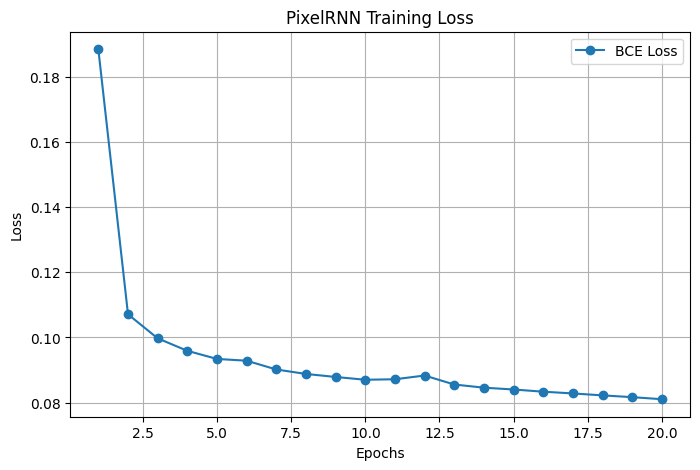

In [244]:
visualize_loss(prnn_epochs, prnn_history, title='PixelRNN Training Loss', label='BCE Loss')


---
## 6 - Model Inference
During inference, we generate one pixel at a time. Each generated pixel probability is sampled and then used as part of the input sequence to predict the next pixel.

---
#### <font color='red'>**EXERCISE:** </font>

    Auto-generate the remaining number of characters up to top_size
    In every loop step:
    1. Get model predictions using 'inputs'
    2. Sample from the Bernoulli distribution based on the calculated probability
    3. Reshape generated_seq into image shape
    

In [245]:
def generate_digits_rnn(model, num_samples=4):
    model.eval()

    with torch.no_grad():
        # Start with an empty collection of sequences initialized to 0
        generated_seq = torch.zeros((num_samples, 784, 1)).to(device)

        ########################################################################
        # TODO: Complete the inference function                                #
        ########################################################################

        # Loop through all 784 pixels sequentially
        for t in range(784):
            # Shift inputs exactly as done during training
            zero_padding = torch.zeros(num_samples, 1, 1).to(device)
            inputs = torch.cat([zero_padding, generated_seq[:, :-1, :]], dim=1)

            # Forward pass 'inputs' into the model()
            probs = model(inputs)

            # Extract the probabilities for the current pixel index 't'
            prob_t = probs[:, t, :]

            # Sample from the Bernoulli distribution based on the calculated probability
            # Use torch.bernoulli() on 'prob_t' to sample binary value (0 or 1)
            sampled_pixel = torch.bernoulli(prob_t)

            # Store the sampled pixel back into our sequence tracker
            generated_seq[:, t, :] = sampled_pixel

        # Reshape the completed sequence back into standard 28x28 image grid format
        generated_images = generated_seq.view(num_samples, 28, 28).cpu().numpy()

        ########################################################################
        #                            END OF YOUR CODE                          #
        ########################################################################

        return generated_images

Run inference generation

In [246]:
# Run inference
print("Generating new images autoregressively...")
prnn_samples = generate_digits_rnn(prnn_model, num_samples=16)

# Verification Check
print(f"Generated samples shape: {prnn_samples.shape}")
assert prnn_samples.shape == (16, 28, 28), "Inference shape is incorrect!"
print("\nGeneration function structural check passed!")

Generating new images autoregressively...
Generated samples shape: (16, 28, 28)

Generation function structural check passed!


**EXPECTED OUTPUT**:
<pre>
Generated samples shape: (16, 28, 28)

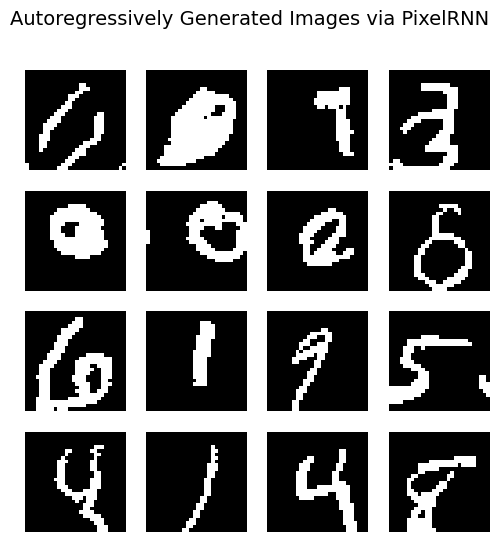

In [247]:
visualize_samples(prnn_samples, title='Autoregressively Generated Images via PixelRNN')

**EXPECTED OUTPUT**:
<pre>
Model should be able to generate pretty good digit images

---
---
#[Part 3] PixelCNN on MNIST

Similar to previous exercise, in this part, you will complete the implementation of a **PixelCNN** model using **PyTorch** to generate MNIST digits.

PixelCNN is also a generative model that models the joint distribution of pixels in an image autoregressively.

Unlike standard convolutional networks that look at an entire image at once, PixelCNN generates pixels one by one, conditioning each new pixel on the previously generated ones (from top-left to bottom-right).

This property requires a specialized mechanism known as Masked Convolutions to prevent the network from "looking into the future."




---
## 1 - Masked Convolution Class
Autoregressive models like PixelCNN require that a pixel's prediction only depends on *previous* pixels.

To enforce this causal structure, we apply a mask to our convolution weights.
- **Mask Type 'A'**: Applied *only* to the first layer. It restricts the center pixel from seeing itself.
- **Mask Type 'B'**: Applied to all subsequent layers. It allows the center pixel to see itself (its own previous features).

---
#### <font color='red'>**EXERCISE:** </font>

     Complete the mask condition for the center pixel based on mask_type
     1. For type 'A', zero out the center pixel (cx, cy) so it cannot look at itself
     2. For type 'B', keep the center pixel as 1
     3. Apply the mask to the weights before executing the forward pass

In [248]:
class MaskedConv2d(nn.Conv2d):
    def __init__(self, mask_type, *args, **kwargs):
        super(MaskedConv2d, self).__init__(*args, **kwargs)
        assert mask_type in {'A', 'B'}
        self.mask_type = mask_type

        # Register mask as a buffer so it moves with the model to the GPU
        self.register_buffer('mask', torch.ones(self.weight.data.size()))
        self.create_mask()


################################################################################
# TODO: Complete the model architecture                                        #
################################################################################

    def create_mask(self):
        # Get height, width, and center coordinates of the kernel
        kh, kw = self.weight.size()[2], self.weight.size()[3]
        cx, cy = kh // 2, kw // 2

        # Zero out rows below the center row
        self.mask[:, :, cx + 1:, :] = 0

        # Zero out pixels to the right of the center pixel in the center row
        self.mask[:, :, cx, cy + 1:] = 0

        if self.mask_type == 'A':
            # set self.mask pixel at (cx, cy) = 0
            self.mask[:, :, cx, cy] = 0

        elif self.mask_type == 'B':
            # set self.mask pixel at (cx, cy) = 1
            self.mask[:, :, cx, cy] = 1

    def forward(self, x):
        # Multiply self.weight by self.mask
        self.weight.data.copy_(self.weight.data * self.mask)

        return super(MaskedConv2d, self).forward(x)

################################################################################
#                                 END OF YOUR CODE                             #
################################################################################


Run this block to ensure that your Masked Convolution behaves exactly as expected.

In [249]:
# Instantiate a 5x5 Mask Type 'A' Convolution
test_layer_a = MaskedConv2d(mask_type='A', in_channels=1, out_channels=1, kernel_size=5, padding=2)
mask_a       = test_layer_a.mask[0, 0].cpu().numpy()

print("Your Type A Mask Structure:\n", mask_a)
expected_a = np.array([
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 0, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0]
])
assert np.allclose(mask_a, expected_a), "Mask Type A implementation is incorrect!"
print("\nMask Type A passes check!")

Your Type A Mask Structure:
 [[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

Mask Type A passes check!


**EXPECTED OUTPUT**:
<pre>
Your Type A Mask Structure:
 [[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

In [250]:
# Instantiate a 5x5 Mask Type 'B' Convolution
test_layer_b = MaskedConv2d(mask_type='B', in_channels=1, out_channels=1, kernel_size=5, padding=2)
mask_b       = test_layer_b.mask[0, 0].cpu().numpy()

print("\nYour Type B Mask Structure:\n", mask_b)
expected_b = np.array([
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0]
])
assert np.allclose(mask_b, expected_b), "Mask Type B implementation is incorrect!"
print("\nMask Type B passes check!")


Your Type B Mask Structure:
 [[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

Mask Type B passes check!


**EXPECTED OUTPUT**:
<pre>
 Your Type B Mask Structure:
 [[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

---
## 2 - PixelCNN Architecture
Now we'll stack multiple `MaskedConv2d` layers to capture longer dependencies. The final layer outputs logit scores for a Bernouli distribution (binary outcome) for each pixel.

---
#### <font color='red'>**EXERCISE:** </font>

    Complete the stack of masked convolutions using SEQUENTIAL API
    1. Add 1 layers of MaskedConv2D A and 3 layers of MaskedConv2D B
    2. Each layer is followed by BatchNorm regularization and ReLU activation function
    3. Add final convolution to output raw logits for 1 channel (binary cross entropy loss takes raw logits)
    4. Pass the input through the sequence network during forward pass

In [251]:
class PixelCNN(nn.Module):
    def __init__(self, hidden_dim=64):
        super(PixelCNN, self).__init__()

        # Complete the stack of masked convolutions
        # Remember: The first layer must be Type 'A'. Subsequent layers must be Type 'B'.
        # Each layer must be followed by BatchNorm and ReLU
        self.net = nn.Sequential(
            # Add the first layer of MaskedConv2d() with Mask 'A', input channels=1, output=hidden_dim, kernel_size=7, padding=3
            MaskedConv2d('A', in_channels=1, out_channels=hidden_dim, kernel_size=7, padding=3),
            nn.BatchNorm2d(hidden_dim),
            nn.ReLU(),

            # Add layer 2 of MaskedConv2d() with Mask 'B', input and output channels=hidden_dim, kernel_size=7, padding=3
            MaskedConv2d('B', in_channels=hidden_dim, out_channels=hidden_dim, kernel_size=7, padding=3),
            nn.BatchNorm2d(hidden_dim),
            nn.ReLU(),

            # Add layer 3 of MaskedConv2d() similar to layer 2
            MaskedConv2d('B', in_channels=hidden_dim, out_channels=hidden_dim, kernel_size=7, padding=3),
            nn.BatchNorm2d(hidden_dim),
            nn.ReLU(),

            # Add layer 4 of MaskedConv2d() similar to layer 2
            MaskedConv2d('B', in_channels=hidden_dim, out_channels=hidden_dim, kernel_size=7, padding=3),
            nn.BatchNorm2d(hidden_dim),
            nn.ReLU(),

            # Add nn.Conv2d() layer with input 'hidden_dim', output=1, and kernel_size=1
            nn.Conv2d(in_channels=hidden_dim, out_channels=1, kernel_size=1)
        )

    def forward(self, x):
        # Pass the input through the sequence network
        return self.net(x)

---
## 3 - Initialize Model and Optimizer

Initialize your model.

You can try and change the hidden dimensions

In [252]:
pcnn_hidden_dim  = 64
pcnn_model       = PixelCNN(hidden_dim=pcnn_hidden_dim).to(device)

print(pcnn_model)

PixelCNN(
  (net): Sequential(
    (0): MaskedConv2d(1, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaskedConv2d(64, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaskedConv2d(64, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): MaskedConv2d(64, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): Conv2d(64, 1, kernel_size=(1, 1), stride=(1, 1))
  )
)


**EXPECTED OUTPUT**:
<pre>
PixelCNN(
  (net): Sequential(
    (0): MaskedConv2d(1, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaskedConv2d(64, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaskedConv2d(64, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): MaskedConv2d(64, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): Conv2d(64, 1, kernel_size=(1, 1), stride=(1, 1))
  )
)

In [253]:
test_input = torch.zeros(2, 1, 28, 28).to(device)
test_output = pcnn_model(test_input)

print(f"Model Output Shape: {test_output.shape}")
assert list(test_output.shape) == [2, 1, 28, 28], "Output dimensions must match input dimensions!"
print("\nModel forward shape test passed!")

Model Output Shape: torch.Size([2, 1, 28, 28])

Model forward shape test passed!


**EXPECTED OUTPUT**:
<pre>
Model Output Shape: torch.Size([2, 1, 28, 28])

Initialize optimizer and learning rate.
For this one, let's try using `BCEWithLogitsLoss` because our pixels are binarized (0 or 1).

In [254]:
pcnn_learning_rate = 0.002

pcnn_optimizer = optim.Adam(pcnn_model.parameters(), lr=pcnn_learning_rate)
pcnn_criterion = nn.BCEWithLogitsLoss()

---
## 4 - Training Loop

Define the training loop function.

Very similar with PixelRNN.

---
#### <font color='red'>**EXERCISE:** </font>

    Complete the missing execution parts
    1. Clear the gradients of the optimizer
    2. Forward pass through the model using 'inputs'
    3. Compute the loss using 'criterion' comparing 'outputs' against true 'images'
    4. Backward pass to compute gradients
    5. Update weights using the optimizer step
    


In [255]:
def pixelcnn_train_module(model, optimizer, epochs=1, print_every=1):
  loss_history = []

  print("Starting PixelCNN training loop...")

  model.train()

  for epoch in range(1, epochs + 1):
      epoch_loss = 0

      for batch_idx, (images, _) in enumerate(mnist_train_loader):
          images = images.to(device)

          # Zero out accumulated gradients
          optimizer.zero_grad()

          # Forward pass 'images' through the model
          outputs = model(images)

          # Compute the loss using 'pcnn_criterion()'
          loss = pcnn_criterion(outputs, images)

          # Backward pass to compute gradients
          loss.backward()

          # Update weights
          optimizer.step()

          epoch_loss += loss.item()

      avg_loss = epoch_loss / len(mnist_train_loader)
      loss_history.append(avg_loss)

      if epoch % print_every == 0 or epoch == 1:
          print(f"Epoch {epoch}/{epochs} --- Avg Loss: {avg_loss:.4f}")

  print("Training Completed!")
  return loss_history

In [256]:
# Training hyperparameters config
pcnn_epochs = 5 # change for longer training and better results

pcnn_history = pixelcnn_train_module(pcnn_model, pcnn_optimizer, pcnn_epochs)

assert pcnn_history[-1]<0.09, f"Loss is not low enough, train more"
print("\nExercise check passed! PixelCNN has been sufficiently trained.")

Starting PixelCNN training loop...
Epoch 1/5 --- Avg Loss: 0.1045
Epoch 2/5 --- Avg Loss: 0.0829
Epoch 3/5 --- Avg Loss: 0.0811
Epoch 4/5 --- Avg Loss: 0.0801
Epoch 5/5 --- Avg Loss: 0.0794
Training Completed!

Exercise check passed! PixelCNN has been sufficiently trained.


**EXPECTED OUTPUT**:
<pre>
Loss should start at around 0.10 and ends at around 0.07 in just 5 epochs

---
## 5 - Metrics Visualization

Visualizing Loss during training

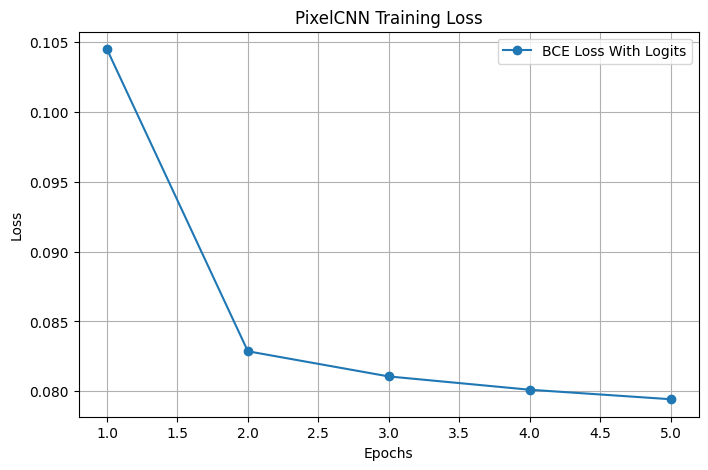

In [257]:
visualize_loss(pcnn_epochs, pcnn_history, title='PixelCNN Training Loss', label='BCE Loss With Logits')


---
## 6 - Model Inference
To generate images, we must sample pixels one by one from top-left to bottom-right. We pass the current state of our canvas to the model, fetch predictions for the next pixel, use a sigmoid to convert logits to probabilities, sample from that distribution, and store it back into the canvas.

---
#### <font color='red'>**EXERCISE:** </font>

    Auto-generate the pixel of a blank canvas from top-left to bottom-right
    In every loop step:
    1. Get model predictions using 'sample'
    2. Isolate the logit score for the current pixel (h, w)
    3. Map logits to probability using sigmoid
    4. Sample from the Bernoulli distribution based on the calculated probability
    5. Assign the sampled pixels back into our blank canvas grid
    

In [258]:
def generate_digits_cnn(model, num_samples=16):
    model.eval()

    # Initialize a blank canvas filled with zeros
    samples = torch.zeros(num_samples, 1, 28, 28).to(device)

    with torch.no_grad():

        # Loop over every row and column sequentially
        for h in range(28):
            for w in range(28):

                # Forward pass on the current 'samples' grid into the model
                logits = model(samples)

                # Select all samples, channel 0, height h, width w from logits
                pixel_logits = logits[:, 0, h, w]

                # Apply torch.sigmoid() function to 'pixel_logits'
                probs = torch.sigmoid(pixel_logits)

                # Use torch.bernoulli() on 'probs' to draw binary choices
                sampled_pixels = torch.bernoulli(probs)

                # Inject sampled_pixels into samples[:, 0, h, w]
                samples[:, 0, h, w] = sampled_pixels

    return samples.cpu()

Run inference generation

In [259]:
# Run generation function
print("Generating new images autoregressively...")
pcnn_samples = generate_digits_cnn(pcnn_model, num_samples=16)

# Verification Check
print(f"Generated samples shape: {pcnn_samples.shape}")
assert list(pcnn_samples.shape) == [16, 1, 28, 28], "Incorrect inference tensor shape!"
print("\nGeneration function structural check passed!")

Generating new images autoregressively...
Generated samples shape: torch.Size([16, 1, 28, 28])

Generation function structural check passed!


**EXPECTED OUTPUT**:
<pre>
Generated samples shape: torch.Size([16, 1, 28, 28])


Let's look at what our model has learned! The images might look slightly noisy due to only training for 5 epochs, but distinct digital structures or shapes should start forming.

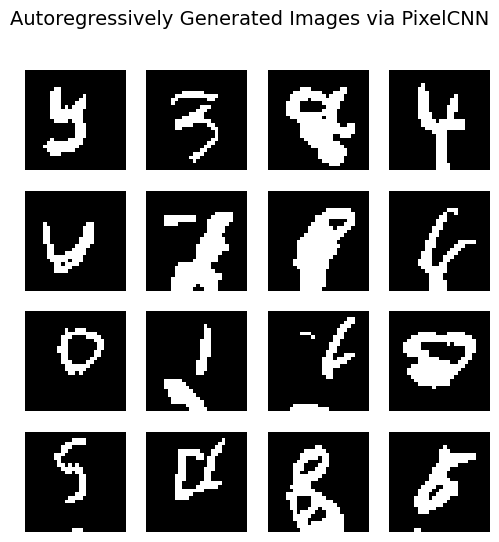

In [260]:
visualize_samples(pcnn_samples[:,0,:,:], title='Autoregressively Generated Images via PixelCNN')

**EXPECTED OUTPUT**:
<pre>
Model should be able to generate pretty good digit images


---

# Congratulation, You've Completed Exercise 02

<p>Copyright &copy;  <a href=https://www.linkedin.com/in/andityaarifianto/>2026 - ADF</a> </p>

![footer](https://i.imgur.com/UU76cTP.png)